
**PROYECTO:** **Modelado espacial para estimar la susceptibilidad a inundaciones usando algoritmos de aprendizaje automatico con datos geomorfologicos**

Autor: Sebastian Velosa Bohorquez. Curso: Percepción Remota Avanzada.




## **Notebook 03/07** : **"Comparación Altimetrica"**

**Objetivo:** Evaluar la concordancia de los DEM con las cotas de los puntos altimétricos de la Red de Control Vertical de Precision IGAC.

**Herramientas:** Google Earth Engine + Google Colab.

**Datos:** DEM/DTM COPERNICUS GLO 30, FABDEM, ANADEM. SHAPE AREA ZONA DE ESTUDIO. PUNTOS RED DE CONTROL VERTICAL, IGAC

**Contenido**
1. Instalación de Librerias
2. Carga y configuración de datos.
3. Verificacion de datos Red de control Vertical
4. Extraer valores de altura DEM/DTM por cada Punto de Referencia
5. Gráfico de dispersión de alturas DEM/DTM vs. alturas de Red de control vertical referencia.
6. Gráfico de distribución de errores por DEM/DTM
(1) cargar datos, (2) extraer elevaciones, (3) calcular errores y métricas, (4) generar gráficos y exportar resultados.
7. Resumen estadístico
8. Exportar resultados

**Resultados:**
Dos archivos csv con las alturas obtenidas y los errores por punto

*   alturas_y_errores_por_punto.csv
*   resumen_metricas_DEM.csv




## 1. Instalar e importar librerías

In [ ]:
!pip -q install geopandas rasterio pyogrio

from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import pyogrio
from IPython.display import display

## 2. Carga y configuración de archivos
Edita las rutas para que coincidan con los archivos DEM/DTM descargados en Google Drive en el Notebook_01. Se incluyen tres archivos `".tiff"`, y un archivo `".gpkg"` con puntos de la Red vertical de precision.

>Notas: Los DEM/DTM fueron reproyectados en el `notebook_01` al SRC - EPSG:31972 — SIRGAS 2000 / UTM zona 18N. La reproyección horizontal no corrige diferencias de datum vertical.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

# EDITAR estas rutas
puntos_ref_vertical = Path('/content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/RED_DATOS_V2.gpkg')
DEM_archivos = {
    'FABDEM': Path('/content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/DEM_alineados/FABDEM_Sinu_V12_alineado.tif'),
    'Copernicus': Path('/content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/DEM_alineados/Copernicus_GLO30_Sinu_alineado.tif'),
    'ANADEM': Path('/content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/DEM_alineados/ANADEM_Sinu_alineado.tif'),
}

# Campo con la cota de altura de referencia conocida en metros de puntos_ref_vertical
campo_altura = 'altura_msn'

print('Capas del GeoPackage:')
print(pyogrio.list_layers(puntos_ref_vertical))
print('\nDEM encontrados:')
for nombre, ruta in DEM.items():
    print(f'{nombre}: {ruta.exists()} — {ruta}')

Capas del GeoPackage:
[['RED_DATOS_V2' 'Point']]

DEM encontrados:
FABDEM: True — /content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/DEM_alineados/FABDEM_Sinu_V12_alineado.tif
Copernicus: True — /content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/DEM_alineados/Copernicus_GLO30_Sinu_alineado.tif
ANADEM: True — /content/drive/MyDrive/Sinu_Flood_Susceptibility/02_Data_raw/DEM_alineados/ANADEM_Sinu_alineado.tif


## 3.  Verificacion de datos Red de control Vertical


In [ ]:
CAPA_PUNTOS = None # Deja `None` para usar la capa predeterminada.

if CAPA_PUNTOS:
    puntos = gpd.read_file(puntos_ref_vertical, layer=CAPA_PUNTOS)
else:
    puntos = gpd.read_file(puntos_ref_vertical)

if puntos.crs is None:
    raise ValueError('El GeoPackage no tiene CRS definido. Asigna el CRS correcto antes de continuar.')
if campo_altura not in puntos.columns:
    raise ValueError(f'No existe {campo_altura}. Campos: {puntos.columns.tolist()}')
if not all(g.geom_type == 'Point' for g in puntos.geometry.dropna()):
    raise ValueError('La capa debe contener geometrías de tipo punto.')

# Convierte cotas a número, incluso si usan coma decimal
puntos[campo_altura] = pd.to_numeric(
    puntos[campo_altura].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)
puntos = puntos[
    puntos.geometry.notna() & ~puntos.geometry.is_empty &
    puntos[campo_altura].notna()
].copy()

print(f'Puntos válidos: {len(puntos)}')
print(f'CRS de los puntos: {puntos.crs}')
display(puntos[[campo_altura]].describe().round(2))

Puntos válidos: 60
CRS de los puntos: EPSG:31972


,altura_msn
count,60.00
mean,45.32
std,47.93
min,7.25
25%,12.84
50%,22.18
75%,55.55
max,202.08


## 4. Extraer valores de altura DEM/DTM por cada Punto de Referencia
Para cada punto, se lee el valor del píxel que contiene su ubicación. Se descartan NoData y el valor centinela `-9999`, frecuente en rásteres.

**Criterio de error:** `error = elevación DEM − elevacion de punto de referencia`. Un error positivo indica sobreestimación; uno negativo, subestimación.

In [ ]:
resultados = pd.DataFrame(index=puntos.index)
resultados['altura_punto_m'] = puntos[campo_altura]

for nombre, ruta in DEM_archivos.items():
    if not Path(ruta).exists():
        print('No se encontró:', nombre)
        continue

    with rasterio.open(ruta) as dem:
        puntos_dem = puntos.to_crs(dem.crs)
        coordenadas = [(p.x, p.y) for p in puntos_dem.geometry]
        alturas = np.array([valor[0] for valor in dem.sample(coordenadas)], dtype=float)

        validos = np.isfinite(alturas)
        if dem.nodata is not None:
            validos = validos & (alturas != dem.nodata)
        validos = validos & (alturas != -9999)
        alturas[~validos] = np.nan

        resultados[nombre + '_m'] = alturas
        resultados[nombre + '_error_m'] = alturas - puntos[campo_altura].to_numpy()

    print(nombre, '| CRS:', dem.crs, '| resolución:', dem.res)

print('Primeros resultados:')
display(resultados.head())

FABDEM | CRS: EPSG:31972 | resolución: (30.0, 30.0)
Copernicus | CRS: EPSG:31972 | resolución: (30.0, 30.0)
ANADEM | CRS: EPSG:31972 | resolución: (30.0, 30.0)
Primeros resultados:


,altura_punto_m,FABDEM_m,FABDEM_error_m,Copernicus_m,Copernicus_error_m,ANADEM_m,ANADEM_error_m
0,45.68243,47.959999,2.277569,48.816208,3.133778,48.630001,2.947571
1,45.59537,47.799999,2.204629,48.066746,2.471376,45.700001,0.104631
2,35.33851,36.380001,1.041491,36.513680,1.175170,35.970001,0.631491
3,17.44756,20.400000,2.952440,20.686766,3.239206,19.530001,2.082441
4,18.77288,20.610001,1.837121,20.846052,2.073172,19.020000,0.247120


## 5. Gráfico de dispersión de alturas DEM/DTM vs. alturas de Red vertical referencia.

- Eje X: altura obtenida de los puntos Red vertical de precision IGAC.
- Eje Y: altura extraída de cada DEM.
- Línea central: línea 1:1 (Y = X), que representa coincidencia perfecta.
Cuanto más cerca estén los puntos de la línea, mayor es la concordancia.

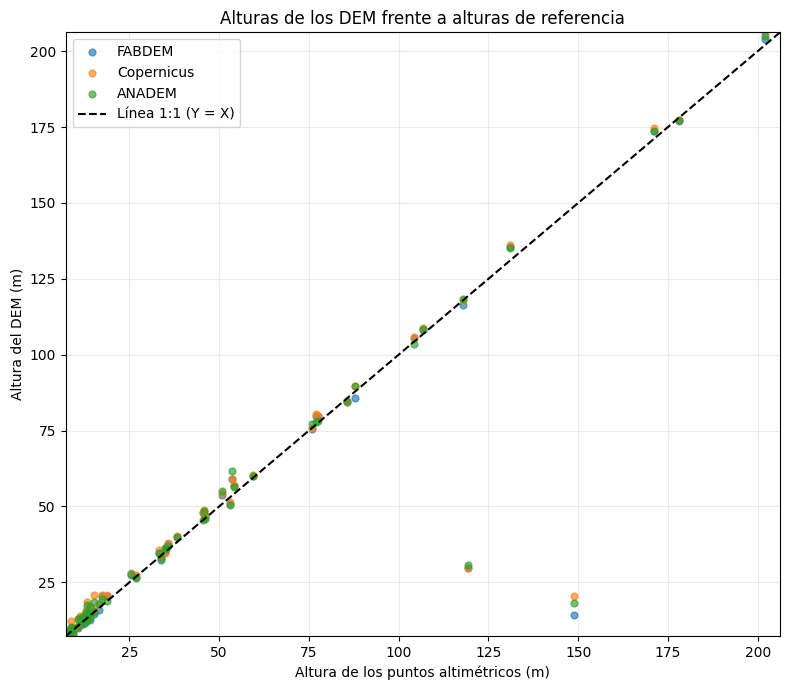

In [ ]:
plt.figure(figsize=(8, 7))

alturas_puntos = resultados['altura_punto_m'].to_numpy()
valores = [alturas_puntos]

for nombre in DEM_archivos:
    if nombre + '_m' in resultados.columns:
        valores.append(resultados[nombre + '_m'].to_numpy())

valores = np.concatenate(valores)
valores = valores[np.isfinite(valores)]
minimo, maximo = valores.min(), valores.max()

colores = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

for i, nombre in enumerate(DEM_archivos):
    columna = nombre + '_m'
    if columna not in resultados.columns:
        continue

    alturas_dem = resultados[columna].to_numpy()
    validos = np.isfinite(alturas_puntos) & np.isfinite(alturas_dem)

    plt.scatter(
        alturas_puntos[validos], alturas_dem[validos],
        s=24, alpha=0.65, color=colores[i % len(colores)],
        label=nombre
    )

plt.plot([minimo, maximo], [minimo, maximo], 'k--', label='Línea 1:1 (Y = X)')
plt.xlabel('Altura de los puntos altimétricos (m)')
plt.ylabel('Altura del DEM (m)')
plt.title('Alturas de los DEM frente a alturas de referencia')
plt.xlim(minimo, maximo)
plt.ylim(minimo, maximo)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

##6. Gráfico de distribución de errores por DEM/DTM
El eje X muestra el error DEM − punto. La línea vertical en cero indica ausencia de diferencia. Errores positivos indican sobreestimación y negativos, subestimación.

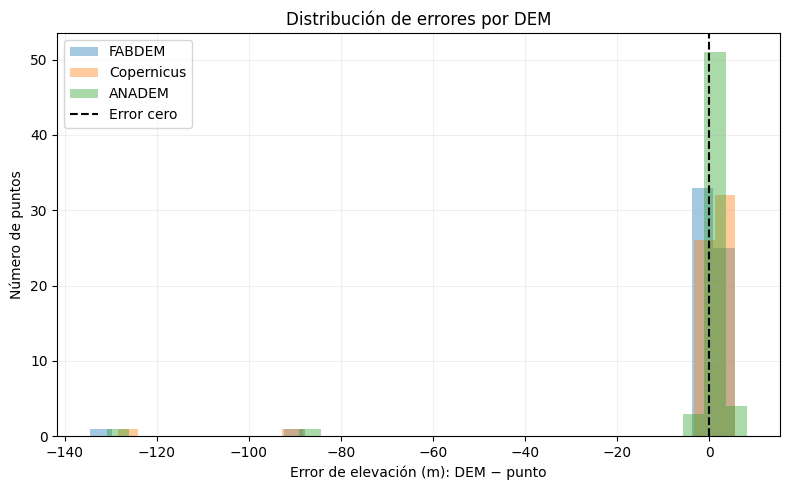

In [ ]:
plt.figure(figsize=(8, 5))

for nombre in DEM_archivos:
    columna = nombre + '_error_m'
    if columna in resultados.columns:
        plt.hist(resultados[columna].dropna(), bins=30, alpha=0.4, label=nombre)

plt.axvline(0, color='black', linestyle='--', label='Error cero')
plt.xlabel('Error de elevación (m): DEM − punto')
plt.ylabel('Número de puntos')
plt.title('Distribución de errores por DEM')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

##7. Resumen estadístico
- ME: Sesgo medio o promedio del error; cercano a cero indica poco sesgo. (Positivo = sobreestimacion)
- MAE: tamaño promedio del error absoluto.
- RMSE: da mayor peso a los errores grandes.
- N: cantidad de puntos válidos.



In [ ]:
resumen = []

for nombre in DEM_archivos:
    columna = nombre + '_error_m'
    if columna not in resultados.columns:
        continue

    errores = resultados[columna].dropna()
    resumen.append({
        'DEM': nombre,
        'N': len(errores),
        'ME (m)': errores.mean(),
        'MAE (m)': errores.abs().mean(),
        'RMSE (m)': np.sqrt((errores ** 2).mean())
    })

tabla_resumen = pd.DataFrame(resumen).sort_values('RMSE (m)')
display(tabla_resumen.round(3))

,DEM,N,ME (m),MAE (m),RMSE (m)
1,Copernicus,60,-2.097,5.435,20.339
2,ANADEM,60,-2.590,5.088,20.486
0,FABDEM,60,-3.075,4.993,20.912


## 7. Exportar resultados
Se guardan la tabla de métricas y una tabla por punto con las cotas y errores de cada DEM.

In [ ]:
carpeta_salida = Path('/content/drive/MyDrive/Sinu_Flood_Susceptibility/06_results/resultados_comparacion_DEM')
carpeta_salida.mkdir(parents=True, exist_ok=True)

resultados.to_csv(carpeta_salida / 'alturas_y_errores_por_punto.csv', index=False)
tabla_resumen.to_csv(carpeta_salida / 'resumen_metricas_DEM.csv', index=False)

print('Resultados guardados en:', carpeta_salida)

Resultados guardados en: /content/drive/MyDrive/Sinu_Flood_Susceptibility/06_results/resultados_comparacion_DEM
